Amazon Top 50 Bestselling Books – Machine Learning Prediction Project

Pandas is used for data handling.
 NumPy is used for numerical operations.
 Matplotlib and Seaborn are used for data visualization.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

The Amazon books dataset is loaded using Pandas.
The first five rows are displayed to understand the dataset.

In [ ]:
data = pd.read_csv("Data.csv")
data.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


 We check the number of rows and columns in the dataset.
This helps us understand the size of the dataset.

In [ ]:
data.shape

(550, 7)

 We check the column names, data types, and non-null values.
 This helps us understand the structure of the dataset.

In [ ]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         550 non-null    str    
 1   Author       550 non-null    str    
 2   User Rating  550 non-null    float64
 3   Reviews      550 non-null    int64  
 4   Price        550 non-null    int64  
 5   Year         550 non-null    int64  
 6   Genre        550 non-null    str    
dtypes: float64(1), int64(3), str(3)
memory usage: 30.2 KB


We check for missing values in each column.
This helps us identify columns that need data cleaning.

In [ ]:
data.isnull().sum()

Name           0
Author         0
User Rating    0
Reviews        0
Price          0
Year           0
Genre          0
dtype: int64

We check for duplicate rows in the dataset.
 This helps us identify repeated records before data preprocessing.

In [ ]:
data.duplicated().sum()

np.int64(0)

We create a new `Book_Age` feature using the Year column.
This shows how old each book is relative to 2026.

In [ ]:
data['Book_Age'] = 2026 - data['Year']

We calculate how many books are listed for each author.
This creates a new feature called `Author_Book_Count`.
It helps us understand the experience or popularity of authors in the dataset.

In [ ]:
data['Author_Book_Count'] = data.groupby('Author')['Name'].transform('count')

We divide the books into Low, Medium, and High review categories.
 This helps us understand the popularity level of each book based on its reviews.

In [ ]:
data['Review_Category'] = pd.qcut(
    data['Reviews'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

We divide books into Budget, Medium, and Expensive price categories.
 This helps us understand the pricing level of each book.

In [ ]:
data['Price_Category'] = pd.cut(
    data['Price'],
    bins=[-1, 10, 30, float('inf')],
    labels=['Budget', 'Medium', 'Expensive']
)


 This creates a new feature called `Name_Length`.
 It helps us analyze whether book title length is related to book performance.

In [ ]:
data['Name_Length'] = data['Name'].str.len()

We display the first five rows of the dataset.
 This helps us verify the newly created features.

In [25]:
data.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre,Book_Age,Author_Book_Count,Review_Category,Price_Category,Name_Length
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction,10,1,High,Budget,29
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction,15,4,Low,Medium,17
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction,8,1,High,Medium,39
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction,9,1,High,Budget,22
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction,7,1,Medium,Medium,66


 We convert categorical columns into numerical columns.
`drop_first=True` removes one category from each group to avoid redundant features.
This makes the dataset suitable for Machine Learning models.

In [ ]:
data = pd.get_dummies(
    data,
    columns=['Genre', 'Review_Category', 'Price_Category'],
    drop_first=True
)

We count how many times each author appears in the dataset.
 This creates a new feature called `Author_Frequency`.
 It helps us understand how frequently each author appears in the bestselling list.

In [ ]:
author_count = data['Author'].value_counts()
data['Author_Frequency'] = data['Author'].map(author_count)

We remove the `Name` and `Author` columns from the model dataset.
 These text columns are not directly used for numerical model training.
 The remaining processed features are used for Machine Learning.

In [ ]:
df = data.drop(['Name', 'Author'], axis=1)

We display the first five rows of the dataset.
This helps us verify the changes made during data preprocessing and feature engineering.

In [29]:
data.head()

,Name,Author,User Rating,Reviews,Price,Year,Book_Age,Author_Book_Count,Name_Length,Genre_Non Fiction,Review_Category_Medium,Review_Category_High,Price_Category_Medium,Price_Category_Expensive,Author_Frequency
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,10,1,29,True,False,True,False,False,1
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,15,4,17,False,False,False,True,False,4
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,8,1,39,True,False,True,True,False,1
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,9,1,22,False,False,True,False,False,1
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,7,1,66,True,True,False,True,False,1


We convert Boolean values (`True` and `False`) into numerical values.
 `True` becomes 1 and `False` becomes 0.
This makes the data suitable for Machine Learning models.

In [30]:
bool_cols=data.select_dtypes(include='bool').columns
data[bool_cols]=data[bool_cols].astype(int)

 We display the first five rows of the dataset after preprocessing.
This helps us verify that all numerical conversions and new features are applied correctly.

In [31]:
data.head()

,Name,Author,User Rating,Reviews,Price,Year,Book_Age,Author_Book_Count,Name_Length,Genre_Non Fiction,Review_Category_Medium,Review_Category_High,Price_Category_Medium,Price_Category_Expensive,Author_Frequency
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,10,1,29,1,0,1,0,0,1
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,15,4,17,0,0,0,1,0,4
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,8,1,39,1,0,1,1,0,1
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,9,1,22,0,0,1,0,0,1
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,7,1,66,1,1,0,1,0,1


We visualize the number of books in each genre.
This helps us compare the distribution of Fiction and Non Fiction books.

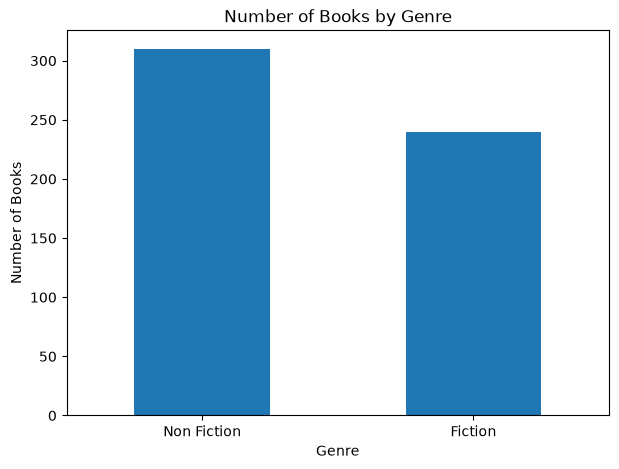

In [ ]:
plt.figure(figsize=(7,5))
data["Genre"].value_counts().plot(kind="bar")
plt.title("Number of Books by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.show()

We visualize the number of bestselling books listed in each year.
This helps us understand how the books are distributed across different years.

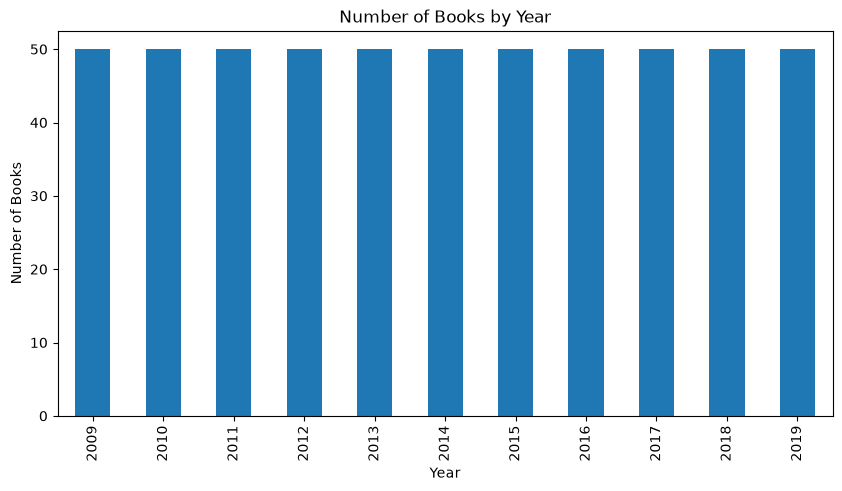

In [ ]:
plt.figure(figsize=(10,5))
data["Year"].value_counts().sort_index().plot(kind="bar")
plt.title("Number of Books by Year")
plt.xlabel("Year")
plt.ylabel("Number of Books")
plt.show()

We calculate the average User Rating for each year.
 The line graph shows how the average rating changes over time.
 This helps us identify yearly trends in book ratings.

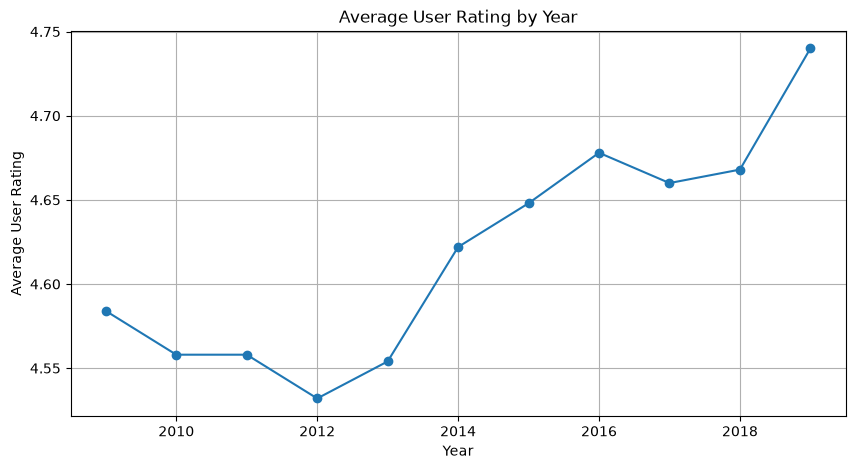

In [ ]:
plt.figure(figsize=(10,5))
data.groupby("Year")["User Rating"].mean().plot(kind="line", marker="o")
plt.title("Average User Rating by Year")
plt.xlabel("Year")
plt.ylabel("Average User Rating")
plt.grid(True)
plt.show()

 We separate the input features from the target variable.
 `User Rating` is selected as the target for prediction.
 The remaining columns are used as input features.

In [10]:
X= data.drop('User Rating', axis=1)
Y= data['User Rating']

We check the number of rows and columns in the input features.
We also check the number of values in the target variable.
 This confirms that the features and target have the expected size.

In [11]:
print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (550, 6)
Y shape: (550,)


We check the data type of each feature in X.
 This helps us identify numerical and categorical columns before model training.

In [20]:
print(X.dtypes)

Name         str
Author       str
Reviews    int64
Price      int64
Year       int64
Genre        str
dtype: object



 Name and Author are removed because they are text-based identifiers.
Reviews, Price, Year, and Genre are retained as useful prediction features.

In [21]:
X = X.drop(["Name", "Author"], axis=1)

print(X.head())
print(X.dtypes)

   Reviews  Price  Year        Genre
0    17350      8  2016  Non Fiction
1     2052     22  2011      Fiction
2    18979     15  2018  Non Fiction
3    21424      6  2017      Fiction
4     7665     12  2019  Non Fiction
Reviews    int64
Price      int64
Year       int64
Genre        str
dtype: object


The Genre column is converted from text into numerical columns.
 This makes the data suitable for Machine Learning models.

In [22]:
X = pd.get_dummies(X, columns=["Genre"], dtype=int)

print(X.head())
print(X.dtypes)

   Reviews  Price  Year  Genre_Fiction  Genre_Non Fiction
0    17350      8  2016              0                  1
1     2052     22  2011              1                  0
2    18979     15  2018              0                  1
3    21424      6  2017              1                  0
4     7665     12  2019              0                  1
Reviews              int64
Price                int64
Year                 int64
Genre_Fiction        int64
Genre_Non Fiction    int64
dtype: object


Split the Dataset

In [26]:
from sklearn.model_selection import train_test_split

Train-Test Split
The dataset is divided into training and testing data.
 80% of the data is used for training and 20% is used for testing

In [27]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Y_train:", Y_train.shape)
print("Y_test:", Y_test.shape)

X_train: (440, 5)
X_test: (110, 5)
Y_train: (440,)
Y_test: (110,)


Linear Regression is used as a baseline model.
 The model learns the relationship between the input features and User Rating.
 Predictions are generated using the test data.


In [ ]:
from sklearn.linear_model import LinearRegression
linear_model = LinearRegression()
linear_model.fit(X_train, Y_train)
linear_pred = linear_model.predict(X_test)
print(linear_pred[:10])

[4.64983636 4.63315985 4.71452859 4.67629715 4.7136969  4.5942303
 4.77869392 4.58249966 4.66276935 4.58896867]


The Decision Tree learns patterns between the features and User Rating.
It can capture non-linear relationships in the data.

In [ ]:
from sklearn.tree import DecisionTreeRegressor
tree_model = DecisionTreeRegressor(random_state=42)
tree_model.fit(X_train, Y_train)
tree_pred = tree_model.predict(X_test)
print(tree_pred[:10])

[4.8 4.3 4.9 4.3 4.8 4.6 4.3 4.6 4.3 4.8]


Random Forest combines multiple decision trees.
It is used to improve prediction performance and reduce overfitting.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
forest_model.fit(X_train, Y_train)
forest_pred = forest_model.predict(X_test)
print(forest_pred[:10])

[4.579 4.485 4.839 4.404 4.596 4.58  4.627 4.675 4.553 4.571]


We compare Linear Regression, Decision Tree, and Random Forest.
 MAE and RMSE measure prediction error.
 R² Score measures how well the model explains the target values.
 The model with better overall performance is selected for the next steps

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
model_names = [
    "Linear Regression",
    "Decision Tree",
    "Random Forest"
]
predictions = [
    linear_pred,
    tree_pred,
    forest_pred
]
for name, pred in zip(model_names, predictions):
    mae = mean_absolute_error(Y_test, pred)
    rmse = np.sqrt(mean_squared_error(Y_test, pred))
    r2 = r2_score(Y_test, pred)
    print(name)
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2 Score:", r2)
    print("-" * 30)

Linear Regression
MAE: 0.16482009426566147
RMSE: 0.22955784515261424
R2 Score: 0.08148756600338458
------------------------------
Decision Tree
MAE: 0.1581818181818182
RMSE: 0.2600699206681996
R2 Score: -0.17891097666378553
------------------------------
Random Forest
MAE: 0.1389727272727263
RMSE: 0.20684168298044198
R2 Score: 0.2542781186977846
------------------------------


We visualize the R² Score of the three models.
 A higher R² Score indicates better prediction performance.
 The graph helps us identify the best performing model.

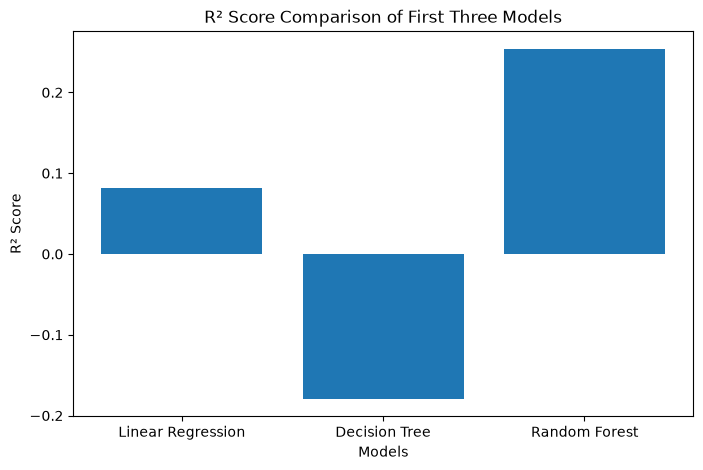

In [32]:
r2_scores = [
    r2_score(Y_test, linear_pred),
    r2_score(Y_test, tree_pred),
    r2_score(Y_test, forest_pred)
]

plt.figure(figsize=(8,5))

plt.bar(model_names, r2_scores)

plt.title("R² Score Comparison of First Three Models")
plt.xlabel("Models")
plt.ylabel("R² Score")

plt.show()

We compare the R² scores of the three models.
 The model with the highest R² Score is selected as the best model.
The selected model will be used for the final prediction.

In [ ]:
scores = {
    "Linear Regression": r2_score(Y_test, linear_pred),
    "Decision Tree": r2_score(Y_test, tree_pred),
    "Random Forest": r2_score(Y_test, forest_pred)
}
best_model_name = max(scores, key=scores.get)
print("Best Model:", best_model_name)
print("Best R2 Score:", scores[best_model_name])

Best Model: Random Forest
Best R2 Score: 0.2542781186977846


Random Forest is selected as the best model based on the model comparison.
 Predictions are generated using the test data.
MAE, RMSE, and R² Score are used to evaluate the final model.


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
best_model = forest_model
best_pred = best_model.predict(X_test)
mae = mean_absolute_error(Y_test, best_pred)
rmse = np.sqrt(mean_squared_error(Y_test, best_pred))
r2 = r2_score(Y_test, best_pred)
print("Best Model:", "Random Forest")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Best Model: Random Forest
MAE: 0.1389727272727263
RMSE: 0.20684168298044198
R2 Score: 0.2542781186977846



 We compare the actual ratings with the predicted ratings.
 The graph helps us understand how closely the Random Forest model predicts the User Rating.

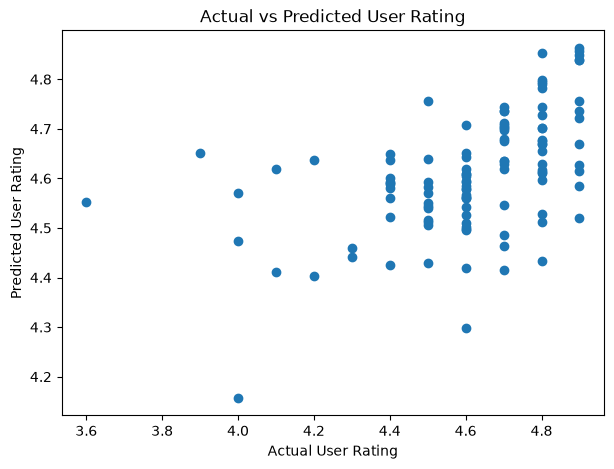

In [ ]:
plt.figure(figsize=(7,5))
plt.scatter(Y_test, best_pred)
plt.xlabel("Actual User Rating")
plt.ylabel("Predicted User Rating")
plt.title("Actual vs Predicted User Rating")
plt.show()

We use the selected Random Forest model to predict User Rating for all books.
 The predicted ratings are added to the dataset.
 The books are sorted according to their predicted ratings.
 The top 50 books with the highest predicted ratings are displayed.

In [ ]:

all_predictions = best_model.predict(X)
data['Predicted_Rating'] = all_predictions
top_50 = data.sort_values(
    by='Predicted_Rating',
    ascending=False
).head(50)
top_50[
    ['Name', 'Author', 'Reviews', 'Price', 'Year',
     'User Rating', 'Predicted_Rating']
]

,Name,Author,Reviews,Price,Year,User Rating,Predicted_Rating
248,"Oh, the Places You'll Go!",Dr. Seuss,21834,8,2015,4.9,4.897
247,"Oh, the Places You'll Go!",Dr. Seuss,21834,8,2014,4.9,4.897
190,Jesus Calling: Enjoying Peace in His Presence ...,Sarah Young,19576,8,2014,4.9,4.896
489,The Wonderful Things You Will Be,Emily Winfield Martin,8842,10,2019,4.9,4.896
479,The Very Hungry Caterpillar,Eric Carle,19546,5,2016,4.9,4.892
249,"Oh, the Places You'll Go!",Dr. Seuss,21834,8,2016,4.9,4.891
478,The Very Hungry Caterpillar,Eric Carle,19546,5,2015,4.9,4.891
252,"Oh, the Places You'll Go!",Dr. Seuss,21834,8,2019,4.9,4.890
189,Jesus Calling: Enjoying Peace in His Presence ...,Sarah Young,19576,8,2013,4.9,4.890
191,Jesus Calling: Enjoying Peace in His Presence ...,Sarah Young,19576,8,2015,4.9,4.888


We display the top 50 books based on the predicted User Rating.
 Actual and predicted ratings are shown for comparison.
This provides the final ranking generated by the Machine Learning model.

In [41]:
top_50[
    ['Name', 'Author', 'Reviews', 'Price', 'Year',
     'User Rating', 'Predicted_Rating']
].reset_index(drop=True)

,Name,Author,Reviews,Price,Year,User Rating,Predicted_Rating
0,"Oh, the Places You'll Go!",Dr. Seuss,21834,8,2015,4.9,4.897
1,"Oh, the Places You'll Go!",Dr. Seuss,21834,8,2014,4.9,4.897
2,Jesus Calling: Enjoying Peace in His Presence ...,Sarah Young,19576,8,2014,4.9,4.896
3,The Wonderful Things You Will Be,Emily Winfield Martin,8842,10,2019,4.9,4.896
4,The Very Hungry Caterpillar,Eric Carle,19546,5,2016,4.9,4.892
5,"Oh, the Places You'll Go!",Dr. Seuss,21834,8,2016,4.9,4.891
6,The Very Hungry Caterpillar,Eric Carle,19546,5,2015,4.9,4.891
7,"Oh, the Places You'll Go!",Dr. Seuss,21834,8,2019,4.9,4.890
8,Jesus Calling: Enjoying Peace in His Presence ...,Sarah Young,19576,8,2013,4.9,4.890
9,Jesus Calling: Enjoying Peace in His Presence ...,Sarah Young,19576,8,2015,4.9,4.888


We visualize the 10 highest-ranked books based on predicted User Rating.
 The graph makes it easier to compare the predicted ratings of the top books.

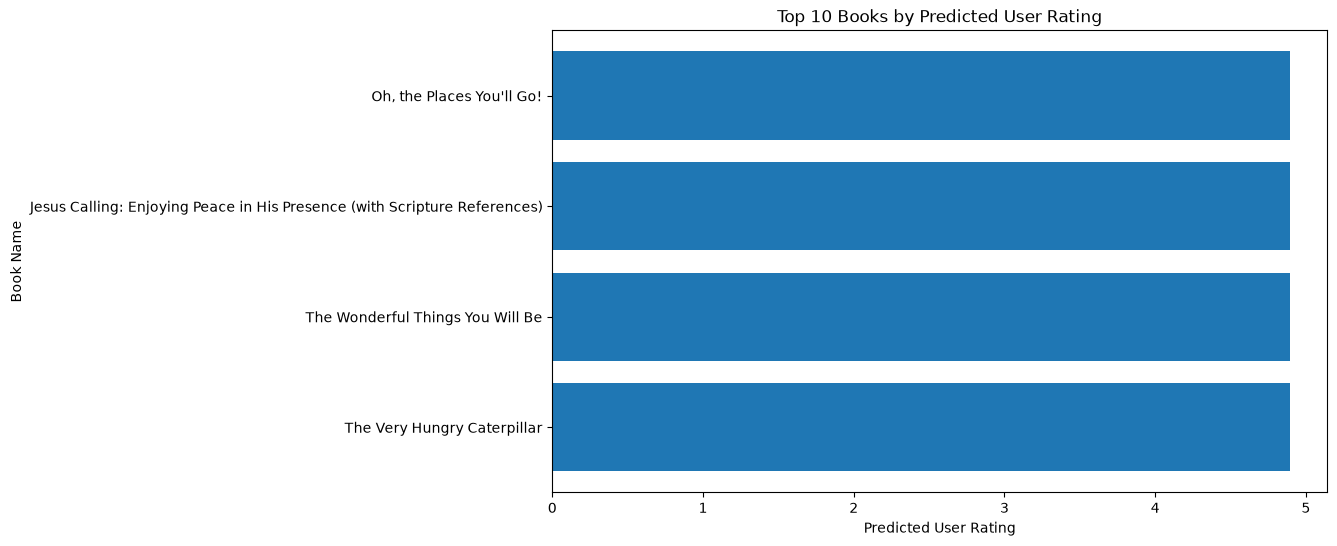

In [ ]:
top_10 = top_50.head(10)
plt.figure(figsize=(10,6))
plt.barh(top_10['Name'], top_10['Predicted_Rating'])
plt.xlabel("Predicted User Rating")
plt.ylabel("Book Name")
plt.title("Top 10 Books by Predicted User Rating")
plt.gca().invert_yaxis()
plt.show()

Final conclusion


 The Amazon Top 50 Bestselling Books dataset was successfully analyzed.
 Data cleaning and preprocessing were performed.
 Missing values and duplicate records were checked.
 New features such as Book Age, Author Book Count, Review Category, Price Category, and Name Length were created.
 Different Machine Learning models were trained and compared.
 Random Forest achieved the highest R² Score among the selected models.
 Therefore, Random Forest was selected as the final model.
 The final model was evaluated using MAE, RMSE, and R² Score.
 The model was used to predict User Ratings for the books.
 Finally, the books were ranked based on their predicted User Ratings and the Top 50 predicted books were identified.